# Figure 4 — publication assembly

Rebuilds `Figure4.png` from the plot-ready data written by `Figure4.ipynb`
(`Figure4_helpers.run_all`). Panels are placed on a millimetre plan; `PAGE_H` is
derived by summing the vertical plan, so it reports the truth if a change makes
the figure too tall.

In [1]:
import os
import sys
import pickle

import numpy as np
import matplotlib
import matplotlib.ticker
from matplotlib import pyplot as plt

FIG4_DIR = '/project2/yangili1/cfbuenabadn/torino_paper/notebooks/Figure4'
ANALYSIS_DIR = '/project2/yangili1/cfbuenabadn/torino_paper/analysis'

# Figure4_helpers reads the isoform / GENCODE beds through '../code/...' paths
os.chdir(ANALYSIS_DIR)
if FIG4_DIR not in sys.path:
    sys.path.append(FIG4_DIR)

import Figure4_plot_helpers as PH
from Figure4_helpers import load_beds

DATA_DIR = os.path.join(FIG4_DIR, 'figure_data')

## Plot-ready data

Every panel reads a pickle from `figure_data/`, except the two pieces the
publication figure adds on top of the exploratory notebook:

* **Panels C / H** — the APPRIS-principal protein-coding transcript of each gene.
  `ITGA1` has exactly one `protein_coding` transcript (`ENST00000282588`);
  `ZSWIM7` has three, and `ENST00000399277` is the one reaching the distal 3'
  end (15,976,560), which is the long terminal block in the reference.
* **Panels E / J** — the torino isoform pairs drawn beneath the factor tracks,
  with the exon to be highlighted in red: the retained intron of `ITGA1`
  isoform 4 (chr5:52,893,675-52,897,528) and the long 3' exon of `ZSWIM7`
  isoform 2 (chr17:15,976,559-15,978,163).

In [2]:
def load_panel_data(data_dir=DATA_DIR):
    """Load every plot-ready pickle, plus the two gene models the figure adds."""
    def L(name):
        with open(os.path.join(data_dir, f'{name}.pkl'), 'rb') as f:
            return pickle.load(f)

    d = {n: L(n) for n in ['itga1_nominal', 'zswim7_nominal',
                           'qtl_barplot', 'upset_data', 'itga1_coverage',
                           'itga1_boxplot', 'itga1_coloc', 'itga1_factors',
                           'zswim7_coverage', 'zswim7_boxplot', 'zswim7_coloc',
                           'zswim7_factors']}

    isoform_bed, gtf_bed = load_beds()

    # Panels C / H: the single APPRIS-principal protein-coding transcript.
    # ITGA1 has exactly one `protein_coding` transcript; ZSWIM7 has three and
    # ENST00000399277 is the one reaching the distal 3' end (15976560), which is
    # the long terminal block in the reference.
    d['itga1_model'] = gene_model(gtf_bed, 'ENSG00000213949', 'ENST00000282588')
    d['zswim7_model'] = gene_model(gtf_bed, 'ENSG00000214941', 'ENST00000399277')

    # Panels E / J: the torino isoform pairs drawn under the factor tracks.
    d['itga1_rows'] = isoform_rows(isoform_bed, 'ITGA1', ['isoform_4', 'isoform_5'],
                                   highlight={'isoform_4': (52893675, 52897528)})
    d['zswim7_rows'] = isoform_rows(isoform_bed, 'ZSWIM7', ['isoform_1', 'isoform_2'],
                                    highlight={'isoform_2': (15976559, 15978163)})
    return d


def gene_model(gtf_bed, gene_id, transcript_id, pad=1000):
    """Exons of one transcript plus the axis span used to draw it."""
    ex = gtf_bed.loc[(gtf_bed.gene_id == gene_id) &
                     (gtf_bed.transcript_id == transcript_id)].sort_values('start')
    lo, hi = int(ex.start.min()) - pad, int(ex.end.max()) + pad
    return {'exons': [(int(r.start), int(r.end)) for _, r in ex.iterrows()],
            'strand': ex.strand.iloc[0], 'axis': (lo, hi)}


def isoform_rows(isoform_bed, gene, transcripts, highlight=None, pad=1000):
    """
    Torino isoform exon rows, with the anchor span that GeneticsPlots uses so the
    minus-strand mirroring matches the factor tracks above them.
    """
    sub = isoform_bed.loc[(isoform_bed.gene_id == gene) &
                          (isoform_bed.transcript_id.isin(transcripts))]
    lo, hi = int(sub.start.min()) - pad, int(sub.end.max()) + pad
    rows = []
    for t in transcripts:
        ex = sub.loc[sub.transcript_id == t].sort_values('start')
        rows.append({'name': t,
                     'exons': [(int(r.start), int(r.end)) for _, r in ex.iterrows()],
                     'highlight': (highlight or {}).get(t)})
    return {'rows': rows, 'strand': sub.strand.iloc[0], 'anchor': (lo, hi)}

## Style and page plan

Nature Genetics double column (180 mm), 5.5-7.5 pt type, 0.5 pt rules,
`pdf.fonttype 42`. `rect()` converts a millimetre box on a top-left origin into
matplotlib figure fractions, so a later "make E 10% shorter" is one constant.

In [3]:
matplotlib.rcParams.update({
    # pdf.fonttype 42 embeds the font as a Type0/CIDFontType2 subset with
    # Identity-H encoding, so the PDF stores glyph *ids*, not characters. Text
    # extracts correctly (there is a ToUnicode map) but Inkscape cannot re-lay
    # it out, which is why editing a label there stacks every letter on one
    # spot. svg.fonttype 'none' keeps text as plain <text> with a font-family
    # name and no embedded glyphs, so the SVG export is the editable one.
    'pdf.fonttype': 42, 'ps.fonttype': 42, 'svg.fonttype': 'none',
    'font.family': 'sans-serif', 'font.sans-serif': ['DejaVu Sans'],
    'axes.linewidth': 0.5, 'xtick.major.width': 0.5, 'ytick.major.width': 0.5,
    'xtick.major.size': 2, 'ytick.major.size': 2,
    'axes.labelsize': 6, 'xtick.labelsize': 6, 'ytick.labelsize': 6,
    'legend.fontsize': 6, 'font.size': 6,
})

# One type scale for the whole figure — no function sets a size inline, so
# changing a level here changes every label that belongs to it. The 5.5 pt floor
# clears the Nature Genetics 5 pt minimum.
FS_TICK = 5.5      # tick labels
FS_ANNOT = 5.5     # in-panel annotation: tissue names, bar counts, rsIDs, keys
FS_LAB = 6.0       # axis labels and in-panel text labels
FS_TITLE = 7.5     # panel and block titles
FS_PANEL = 9       # panel letters
LW = 0.6

# Scatter marker sizes. Matplotlib's `s` is an *area* in pt^2, so a marker of
# diameter d needs s = d**2: doubling a diameter is x4 in `s`, quadrupling is
# x16. Seaborn's stripplot `size` is a diameter in points, so it scales directly.
MS_STRIP = 2.8     # F / K points        (2x the 1.4 pt diameter)
MS_COLOC = 8.0     # G / L background    (2x diameter: s 2.0 -> 8.0)
# lead SNP at 150% of the background *diameter*; derived from MS_COLOC so the
# ratio survives any later change to the background dots
MS_LEAD = MS_COLOC * 1.5 ** 2                       # -> s 18.0, d 4.24 pt

GENO_COLORS = ['darkred', 'orangered', 'gold']          # ref / het / alt
NAVY, RED = 'midnightblue', '#d62728'
CAT_COLORS = {'Intron Retention': '#55B8A9', "Alt. PolyA": '#CCCC47',
              'Cassette Exon': '#8D89C4', 'MXE': '#8D89C4', 'Other': '#8D89C4',
              'Efficiency factor': 'tab:gray'}
INTERSECTION_RED = '#E8402D'

# ---- page plan (mm, top-left origin) ---------------------------------------
PAGE_W = 180.0                 # reference: Nature Genetics double column

M_TOP, M_BOT = 5.5, 3.0
AX, AW = 13.0, 73.5            # panel A axes
# A is tall enough for the longest tissue name to sit inside its bar at
# FS_ANNOT: 'Skin Not Sun Exposed Suprapubic (3403)' needs ~41 mm of column.
A_Y, A_H = M_TOP, 46.0
B_X, B_W = 92.0, 87.0          # panel B block
B_Y = 2.5
B_TITLE_H, B_BAR_H, B_MAT_H = 5.5, 25.0, 19.0
B_TOT_W, B_LAB_W = 9.5, 20.0   # totals strip, category-label gutter

LX, LW_ = 13.0, 107.5          # wide genomic column (C D E H I J)
RX, RW = 142.0, 33.5           # boxplots (F K)
GX, GW = 141.0, 34.5           # scatters (G L)

# absorbs the 8 mm A gained, so Y_BLOCK1 and PAGE_H are unchanged; A and B now
# also share a bottom edge (51.5 vs 52.0 mm)
BLOCK_GAP = 5.5                # A/B block -> ITGA1 block
TITLE_H = 9.0                  # two-line block title
MODEL_H = 5.5                  # gene-model track (C, H)
GAP_MC = 5.0
COV_H = 20.0                   # coverage (D, I) — 2/3 of the original 30 mm
GAP_CE = 6.0
TRACK_H = 14.0 * 0.8           # one factor track (E, J) — 80% of its previous height
IROW_H = 1.9 * 1.5             # one isoform row — 150% of its previous height
IROW_GAP = 0.5
BLOCK_GAP2 = 12.0              # ITGA1 block -> ZSWIM7 block

# vertical plan, summed top-down
Y_BLOCK1 = M_TOP + A_H + BLOCK_GAP                  # ITGA1 block title top
Y_C = Y_BLOCK1 + TITLE_H
Y_D = Y_C + MODEL_H + GAP_MC
Y_E = Y_D + COV_H + GAP_CE
E_H = 2 * TRACK_H + 2 * (IROW_H + IROW_GAP)
Y_BLOCK2 = Y_E + E_H + BLOCK_GAP2                   # ZSWIM7 block title top
Y_H = Y_BLOCK2 + TITLE_H
Y_I = Y_H + MODEL_H + GAP_MC
Y_J = Y_I + COV_H + GAP_CE
J_H = E_H
PAGE_H = Y_J + J_H + M_BOT                          # derived, not typed

# right-column panels, positioned within their block
# the two-line genotype labels (with n) make F and K taller, and the shorter
# E/J blocks pull the page bottom up, so the boxplots lose a few mm and L moves up
F_Y, F_H = Y_C - 2.0, 27.0
G_Y, G_H = Y_C + 36.0, 32.0
K_Y, K_H = Y_H - 6.0, 27.0
L_Y, L_H = Y_H + 31.0, 28.0           # kept clear of the page bottom


def rect(x, y, w, h):
    """mm box with a top-left origin -> matplotlib [left, bottom, w, h] fractions."""
    return [x / PAGE_W, 1.0 - (y + h) / PAGE_H, w / PAGE_W, h / PAGE_H]


def panel_letter(fig, x, y, letter):
    fig.text(x / PAGE_W, 1.0 - y / PAGE_H, letter, fontsize=FS_PANEL,
             fontweight='bold', va='top', ha='left')


def block_title(fig, y, line1, line2):
    # centred over the track column, as in the reference: the long first line
    # would otherwise run into the F / K panel letters
    fig.text((LX + LW_ / 2) / PAGE_W, 1.0 - y / PAGE_H,
             line1 + '\n' + line2, fontsize=FS_TITLE, va='top', ha='center',
             linespacing=1.35)

## Panel drawing

Each function takes plot-ready data and does nothing but draw. Two notes:

* **Panel B** is drawn here rather than by `upsetplot`, which in 0.9 lays out its
  own figure-filling gridspec and will not stay inside a placed sub-figure.
  `upsetplot` still supplies the combinatorics, so the subset ordering and sizes
  are unchanged. The colours differ from the exploratory notebook: each
  single-category bar takes its category colour and **every multi-category
  intersection is red**, instead of the last matching `style_subsets()` call
  winning.
* **Panels D / I** reproduce the smoothing and minus-strand mirroring of
  `GeneticsPlots.plot_coverage` exactly.

In [4]:
def draw_qtl_barplot(ax, qtl):
    """Panel A — factor QTLs per GTEx tissue, tissue ids prettified for print."""
    n = len(qtl['qtls_sorted'])
    ax.bar(range(n), qtl['qtls_sorted'], color=qtl['col_colors_sorted'],
           width=0.8, linewidth=0)
    for i, tissue in enumerate(qtl['tissues_sorted']):
        ax.text(i, 90, f"{tissue.replace('_', ' ')} ({qtl['qtls_sorted'][i]})",
                rotation=90, size=FS_ANNOT, ha='center', va='bottom')
    med = np.median(qtl['qtls_sorted'])
    ax.plot([-0.5, n - 0.5], [med, med], 'r--', linewidth=LW)
    ax.text(n - 1.2, med + 180, f'Median:\n{med}', fontsize=FS_ANNOT,
            ha='right', va='bottom')
    ax.set_xlim(-0.8, n - 0.2)
    ax.set_xticks([])
    ax.set_xlabel('Tissue', fontsize=FS_LAB)
    ax.set_ylabel('Factor QTLs', fontsize=FS_LAB)
    ax.tick_params(labelsize=FS_TICK)
    ax.spines[['top', 'right']].set_visible(False)
    ax.set_title('Torino isoform QTLs across GTEx tissues', fontsize=FS_TITLE, pad=4)


def draw_upset(fig, upset_data):
    """
    Panel B — UpSet of RNA-processing classes across colocalised GWAS loci.

    upsetplot supplies the combinatorics (subset ordering and sizes, category
    totals); the drawing is done here because upsetplot 0.9 lays out its own
    figure-filling gridspec and will not stay inside a placed sub-figure.

    Recoloured against the exploratory notebook: each single-category bar takes
    its category colour and *every* multi-category intersection is red, rather
    than the last matching style_subsets() call winning.
    """
    from upsetplot import UpSet

    u = UpSet(upset_data, sort_categories_by=None, element_size=None)
    inter, totals = u.intersections, u.totals
    cats = list(totals.index)
    memb = inter.index.to_frame(index=False)
    n_cat, n_int = len(cats), len(inter)

    ax_b = fig.add_axes(rect(B_X + B_TOT_W + B_LAB_W, B_Y + B_TITLE_H,
                             B_W - B_TOT_W - B_LAB_W, B_BAR_H))
    ax_m = fig.add_axes(rect(B_X + B_TOT_W + B_LAB_W, B_Y + B_TITLE_H + B_BAR_H,
                             B_W - B_TOT_W - B_LAB_W, B_MAT_H))
    ax_t = fig.add_axes(rect(B_X, B_Y + B_TITLE_H + B_BAR_H, B_TOT_W, B_MAT_H))

    colours = []
    for j in range(n_int):
        present = [c for c in cats if memb.iloc[j][c]]
        colours.append(CAT_COLORS[present[0]] if len(present) == 1
                       else INTERSECTION_RED)

    # --- intersection bars ---
    sizes = list(inter.values)
    ax_b.bar(range(n_int), sizes, color=colours, width=0.62, linewidth=0)
    for j, s in enumerate(sizes):
        ax_b.text(j, s + 5, str(int(s)), ha='center', va='bottom', fontsize=FS_ANNOT)
    ax_b.set_xlim(-0.7, n_int - 0.3)
    ax_b.set_ylim(0, 320)
    ax_b.set_xticks([])
    ax_b.set_ylabel('Intersection size', fontsize=FS_LAB)
    ax_b.tick_params(labelsize=FS_TICK)
    ax_b.grid(axis='y', linewidth=0.3, color='0.6', alpha=0.7)
    ax_b.set_axisbelow(True)
    ax_b.spines[['top', 'right']].set_visible(False)

    # --- membership matrix (row 0 of `cats` at the bottom) ---
    row = {c: n_cat - 1 - i for i, c in enumerate(cats)}
    for c in cats:
        if row[c] % 2 == 0:
            ax_m.axhspan(row[c] - 0.5, row[c] + 0.5, color='0.93', linewidth=0,
                         zorder=0)
    xs = np.repeat(np.arange(n_int), n_cat)
    ys = np.tile(np.arange(n_cat), n_int)
    ax_m.scatter(xs, ys, s=9, color='0.85', zorder=1, linewidth=0)
    for j in range(n_int):
        present = [row[c] for c in cats if memb.iloc[j][c]]
        if len(present) > 1:
            ax_m.plot([j, j], [min(present), max(present)], color=colours[j],
                      linewidth=1.0, zorder=2, solid_capstyle='round')
        ax_m.scatter([j] * len(present), present, s=9, color=colours[j], zorder=3,
                     linewidth=0)
    starred = {'Intron Retention', "Alt. PolyA", 'Cassette Exon', 'MXE'}
    ax_m.set_xlim(-0.7, n_int - 0.3)
    ax_m.set_ylim(n_cat - 0.5, -0.5)
    ax_m.set_xticks([])
    ax_m.set_yticks([row[c] for c in cats])
    ax_m.set_yticklabels([('* ' if c in starred else '') + c for c in cats],
                         fontsize=FS_TICK)
    ax_m.tick_params(axis='y', length=0, pad=1)
    for s in ax_m.spines.values():
        s.set_visible(False)

    # --- category totals, growing leftwards ---
    ax_t.barh([row[c] for c in cats], [totals[c] for c in cats], height=0.55,
              color='black', linewidth=0)
    ax_t.set_ylim(n_cat - 0.5, -0.5)
    ax_t.set_xlim(1000, 0)
    ax_t.set_yticks([])
    ax_t.set_xticks([500, 0])
    ax_t.tick_params(labelsize=FS_TICK, pad=1)
    ax_t.spines[['top', 'right', 'left']].set_visible(False)

    fig.text((B_X + B_W / 2) / PAGE_W, 1.0 - B_Y / PAGE_H,
             'Torino isoform QTLs colocalized with GWAS traits',
             fontsize=FS_TITLE, ha='center', va='top')
    fig.text((B_X + B_TOT_W + B_LAB_W + (B_W - B_TOT_W - B_LAB_W) / 2) / PAGE_W,
             1.0 - (B_Y + B_TITLE_H + B_BAR_H + B_MAT_H + 4.6) / PAGE_H,
             '*Total: 1273 splicing, APA or intron retention events.',
             fontsize=FS_ANNOT, ha='center', va='bottom')
    return ax_b, ax_m, ax_t


def _mirror(v, anchor):
    """Reflect a coordinate into the strand-flipped drawing space."""
    return anchor[0] + anchor[1] - v


def draw_gene_model(ax, model, highlight, label, lw=1.4, min_exon_mm=0.30):
    """
    Panels C / H — one transcript as exon blocks on a connecting line, with the
    region shown in the panels below marked by a red box drawn over the track.

    These panels show a whole gene, so most exons are far thinner than a printed
    line: a 100 bp exon of ITGA1's 173 kb span is 0.06 mm and disappears. Every
    exon is therefore widened about its midpoint to `min_exon_mm` if needed, so
    the exon *count* stays readable. Exons wider than that keep their true width.
    """
    a = model['axis']
    ex = [(_mirror(e, a), _mirror(s, a)) if model['strand'] == '-' else (s, e)
          for s, e in model['exons']]
    lo, hi = min(s for s, _ in ex), max(e for _, e in ex)
    ax.plot([lo, hi], [0.5, 0.5], color='black', linewidth=lw, solid_capstyle='butt')
    min_w = min_exon_mm / LW_ * (a[1] - a[0])
    for s, e in ex:
        if e - s < min_w:
            mid = 0.5 * (s + e)
            s, e = mid - min_w / 2, mid + min_w / 2
        ax.fill_between([s, e], [0, 0], [1, 1], color='black', linewidth=0)
    # highlight is given in axis coordinates (same window as the panels below)
    ax.add_patch(plt.Rectangle((highlight[0], -0.35), highlight[1] - highlight[0], 1.7,
                               facecolor='red', alpha=0.18, edgecolor='red',
                               linewidth=1.0, zorder=5, clip_on=False))
    ax.set_xlim(a)
    ax.set_ylim(-0.5, 1.5)
    ax.set_xticks([]); ax.set_yticks([])
    for s in ax.spines.values():
        s.set_visible(False)
    ax.text(0.035, 1.75, label, transform=ax.transAxes, fontsize=FS_LAB,
            style='italic', ha='left', va='top')


def draw_coverage(ax, cov, strand, xlim, tissue_label, rsid, smooth=100,
                  ylim=None, legend_loc='upper right', legend_anchor=None):
    """
    Panels D / I — genotype-stratified coverage. Reproduces the smoothing and the
    minus-strand mirroring of GeneticsPlots.plot_coverage exactly.
    """
    c = cov['coverage_dir']
    coords = list(c['coords'])
    refs, hets, alts = (list(c['ref_coverage']), list(c['het_coverage']),
                        list(c['alt_coverage']))
    sc = np.array([np.mean(coords[i:i + smooth]) for i in range(len(coords))]) - smooth
    sa = [np.mean(alts[i:i + smooth]) for i in range(len(alts))]
    sh = [np.mean(hets[i:i + smooth]) for i in range(len(hets))]
    sr = [np.mean(refs[i:i + smooth]) for i in range(len(refs))]

    ref, alt = c['ref_allele'], c['alt_allele']
    var_pos = c['var_pos']
    if strand == '-':
        sa, sh, sr = sa[::-1], sh[::-1], sr[::-1]
        var_pos = sc[-1] + sc[0] - var_pos

    ax.plot(sc, sa, label=f'{alt}/{alt}', c=GENO_COLORS[2], linewidth=LW)
    ax.plot(sc, sh, label=f'{ref}/{alt}', c=GENO_COLORS[1], linewidth=LW)
    ax.plot(sc, sr, label=f'{ref}/{ref}', c=GENO_COLORS[0], linewidth=LW)

    top = ylim if ylim else np.nanmax([np.nanmax(sa), np.nanmax(sh), np.nanmax(sr)])
    ax.plot([var_pos, var_pos], [0, top], linestyle='--', c='red', linewidth=LW)
    ax.text(var_pos, top * 1.02, rsid, color='red', fontsize=FS_ANNOT,
            ha='center', va='bottom')

    ax.set_xlim(xlim)
    ax.set_ylim(-0.02 * top, top * 1.0)
    ax.set_xticks([])
    # the short axis otherwise picks decimal ticks (0.0, 2.5, ...)
    ax.yaxis.set_major_locator(
        matplotlib.ticker.MaxNLocator(nbins=3, integer=True, steps=[1, 2, 5, 10]))
    ax.set_ylabel('normalized counts', fontsize=FS_LAB)
    ax.tick_params(labelsize=FS_TICK)
    ax.spines[['top', 'right', 'bottom']].set_visible(False)
    ax.legend(frameon=False, fontsize=FS_ANNOT, loc=legend_loc, handlelength=1.2,
              borderpad=0.1, labelspacing=0.25,
              **({'bbox_to_anchor': legend_anchor} if legend_anchor else {}))
    ax.text(0.015, 0.98, f'Read counts in {tissue_label}', transform=ax.transAxes,
            fontsize=FS_LAB, ha='left', va='top')


def draw_isoform_row(ax, row, strand, anchor, xlim, lw=1.2):
    """One torino isoform track; the highlighted exon is drawn red."""
    hl = row['highlight']
    ex = []
    for s, e in row['exons']:
        red = hl is not None and s == hl[0] and e == hl[1]
        ex.append(((_mirror(e, anchor), _mirror(s, anchor)) if strand == '-'
                   else (s, e)) + (red,))
    lo, hi = min(s for s, _, _ in ex), max(e for _, e, _ in ex)
    ax.plot([lo, hi], [0.5, 0.5], color=NAVY, linewidth=lw, solid_capstyle='butt')
    for s, e, red in ex:
        ax.fill_between([s, e], [0, 0], [1, 1], color=RED if red else NAVY,
                        linewidth=0, zorder=3)
    ax.set_xlim(xlim)
    ax.set_ylim(0, 1)
    ax.set_xticks([]); ax.set_yticks([])
    for s in ax.spines.values():
        s.set_visible(False)


def draw_factor_block(fig, y, factors, rows, factor_list, colors, labels, xlim):
    """
    Panels E / J — each factor track with its own isoform model directly under
    it (track, isoform, track, isoform), so a TP and the structure it describes
    read as one unit.

    The left-hand label carries the isoform name in its parenthesis and takes
    the track's colour; the isoform rows are not labelled again on the right.
    Block height is unchanged: 2 tracks + 2 rows, same as the stacked version.
    """
    track_axes, row_axes, cursor = [], [], y
    for i in range(len(factor_list)):
        track_axes.append(fig.add_axes(rect(LX, cursor, LW_, TRACK_H)))
        cursor += TRACK_H
        row_axes.append(fig.add_axes(rect(LX, cursor, LW_, IROW_H)))
        cursor += IROW_H + IROW_GAP

    PH.plot_factors_wrapper(factors['EF_smooth'], factors['coords'], '',
                            factor_list=factor_list, xlim=xlim, mute_y_axis=True,
                            ax=track_axes, strand=rows['strand'], colores=colors,
                            lwidth=LW)
    for ax, lab, col in zip(track_axes, labels, colors):
        ax.set_xticks([])
        for s in ax.spines.values():
            s.set_visible(False)
        ax.text(-0.028, 0.55, lab, transform=ax.transAxes, fontsize=FS_LAB,
                ha='left', va='center', linespacing=1.3, color=col)

    for ax, row in zip(row_axes, rows['rows']):
        draw_isoform_row(ax, row, rows['strand'], rows['anchor'], xlim)
    return track_axes


def format_nominal(stat, digits=2):
    """The factor-QTL nominal-pass statistic, headed by what produced it."""
    return (f"Nominal cis-QTL results:\n"
            f"$\\beta$ = {stat['beta']:.{digits}f}, "
            f"p = {stat['pval']:.1e}")


def draw_boxplot(ax, df, isoform, gene, iso_label, tissue, rsid, color,
                 nominal=None, nominal_loc='upper left'):
    """
    Panels F / K — normalised usage by genotype.

    `nominal` is the factor-QTL nominal-pass record for this isoform-variant
    pair (Figure4_helpers.prepare_nominal_stat): its slope and p-value are the
    QTL model's own, not a fit to the plotted points, so they account for the
    covariates the QTL pass used and are what the coloc scatters above are
    built from.
    """
    import seaborn as sns
    sns.boxplot(data=df, x='genotype', y=isoform, width=.55, fliersize=0,
                linewidth=LW, patch_artist=True, ax=ax, hue='genotype',
                legend=False,
                boxprops=dict(edgecolor=color, facecolor='white'),
                whiskerprops=dict(color=color, linewidth=LW),
                capprops=dict(color=color, linewidth=LW),
                medianprops=dict(color=color, linewidth=LW))
    # not rasterised: 107 and 102 points, cheap to keep as vector
    sns.stripplot(data=df, x='genotype', y=isoform, c=color, alpha=0.4, ax=ax,
                  size=MS_STRIP, jitter=0.22)
    # sample size per genotype. The labels are read back from the axes rather
    # than re-specified, so seaborn's own category order is preserved exactly.
    counts = df.genotype.value_counts()
    labs = [t.get_text() for t in ax.get_xticklabels()]
    ax.set_xticks(range(len(labs)))
    ax.set_xticklabels([f'{g}\n(n={int(counts.get(g, 0))})' for g in labs],
                       fontsize=FS_TICK)
    ax.set_ylabel(f'$\\mathit{{{gene}}}$ {iso_label}\nnormalized usage\n({tissue})',
                  fontsize=FS_LAB, linespacing=1.4)
    ax.set_xlabel(rsid, fontsize=FS_LAB)
    ax.tick_params(labelsize=FS_TICK)
    ax.spines[['top', 'right']].set_visible(False)

    if nominal is not None:
        # headroom so the text does not sit on a box or whisker
        lo, hi = ax.get_ylim()
        if nominal_loc.startswith('upper'):
            ax.set_ylim(lo, hi + 0.26 * (hi - lo))   # two lines of note
        xy = {'upper left': (0.02, 0.98, 'left', 'top'),
              'upper right': (0.98, 0.98, 'right', 'top'),
              'lower left': (0.02, 0.02, 'left', 'bottom'),
              'lower right': (0.98, 0.02, 'right', 'bottom')}[nominal_loc]
        ax.text(xy[0], xy[1], format_nominal(nominal), transform=ax.transAxes,
                ha=xy[2], va=xy[3], fontsize=FS_ANNOT, color='black',
                linespacing=1.3)
        ax.nominal_ = nominal


def draw_coloc(ax, df, lead_var, rsid, gene, iso_label, tissue, trait,
               label_offset, ha='left'):
    """Panels G / L — GWAS vs factor-QTL -log10 p-values."""
    # not rasterised: ~2.9k and ~2.6k variants, one PathCollection each, which
    # is well inside what a vector PDF handles (the Figure 1 blow-up was tens of
    # thousands of separate rasterised groups, not one big collection)
    ax.scatter(-np.log10(df.pval_x), -np.log10(df.pval_y), facecolor='none',
               edgecolor='black', s=MS_COLOC, linewidth=0.3)
    lead = df.loc[df.var_id == lead_var]
    lx, ly = float(-np.log10(lead.pval_x.iloc[0])), float(-np.log10(lead.pval_y.iloc[0]))
    ax.scatter(lx, ly, c='red', s=MS_LEAD, zorder=5, linewidth=0)
    ax.text(lx + label_offset[0], ly + label_offset[1], rsid, c='red',
            fontsize=FS_ANNOT, ha=ha, va='center')
    ax.set_xlabel(f'-log10 pval {trait}', fontsize=FS_LAB)
    ax.set_ylabel(f'-log10 pval $\\mathit{{{gene}}}$ {iso_label}\n({tissue})',
                  fontsize=FS_LAB, linespacing=1.4, labelpad=1)
    ax.tick_params(labelsize=FS_TICK)
    ax.spines[['top', 'right']].set_visible(False)

## Assembly

page: 180.0 x 221.2 mm


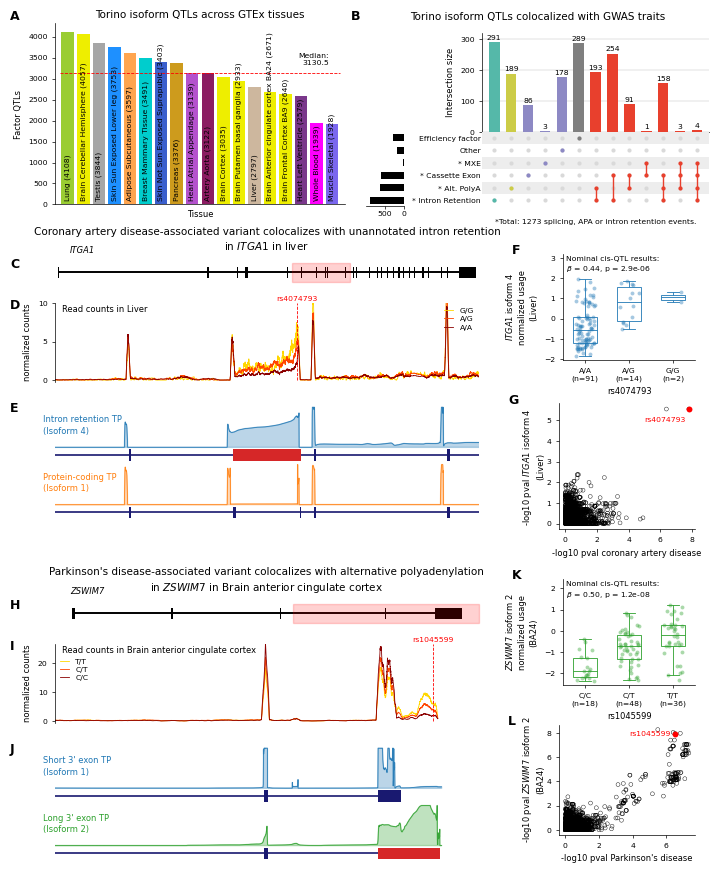

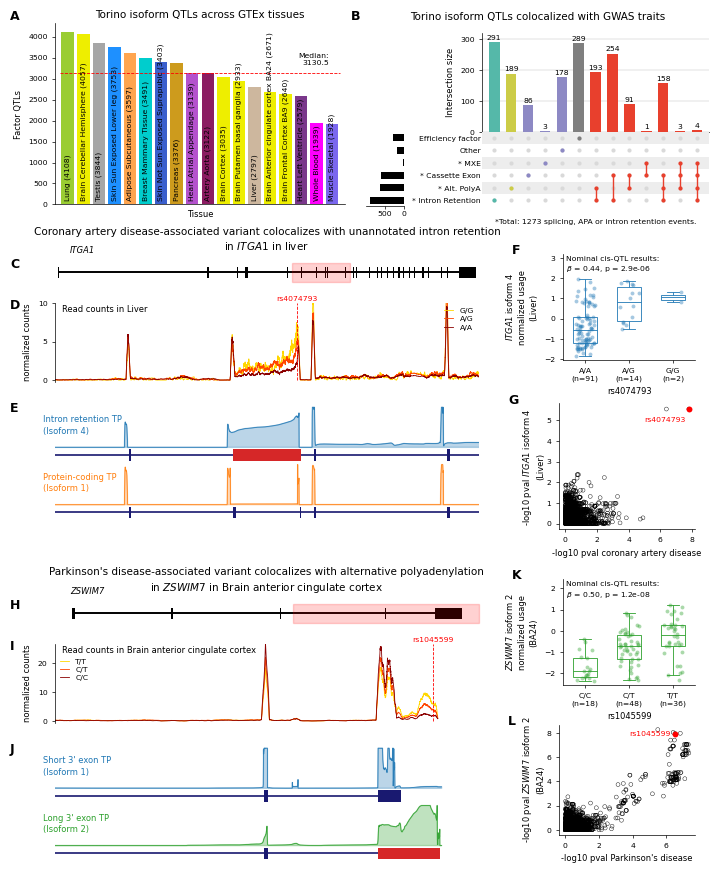

In [5]:
ITGA1_XLIM = (52893675 - 10000, 52897528 + 10000)
ZSWIM7_XLIM = (15999710 - 10000, 15999710 + 1000)


def build_figure(d=None):
    if d is None:
        d = load_panel_data()

    fig = plt.figure(figsize=(PAGE_W / 25.4, PAGE_H / 25.4))

    # ---- A ---------------------------------------------------------------
    panel_letter(fig, 1.5, 2.0, 'A')
    draw_qtl_barplot(fig.add_axes(rect(AX, A_Y, AW, A_H)), d['qtl_barplot'])

    # ---- B ---------------------------------------------------------------
    panel_letter(fig, B_X - 4.0, 2.0, 'B')
    draw_upset(fig, d['upset_data'])

    # ---- ITGA1 block -----------------------------------------------------
    block_title(fig, Y_BLOCK1,
                'Coronary artery disease-associated variant colocalizes with '
                'unannotated intron retention',
                'in $\\mathit{ITGA1}$ in liver')

    panel_letter(fig, 1.5, Y_C - 1.0, 'C')
    draw_gene_model(fig.add_axes(rect(LX, Y_C, LW_, MODEL_H)), d['itga1_model'],
                    ITGA1_XLIM, 'ITGA1')

    panel_letter(fig, 1.5, Y_D - 1.0, 'D')
    draw_coverage(fig.add_axes(rect(LX, Y_D, LW_, COV_H)), d['itga1_coverage'],
                  '+', ITGA1_XLIM, 'Liver', 'rs4074793', ylim=10)

    panel_letter(fig, 1.5, Y_E - 1.0, 'E')
    draw_factor_block(fig, Y_E, d['itga1_factors'], d['itga1_rows'],
                      ['factor3', 'factor4'], ['tab:blue', 'tab:orange'],
                      ['Intron retention TP\n(Isoform 4)',
                       'Protein-coding TP\n(Isoform 1)'],
                      ITGA1_XLIM)

    panel_letter(fig, RX - 13.0, F_Y - 2.5, 'F')
    draw_boxplot(fig.add_axes(rect(RX, F_Y, RW, F_H)), d['itga1_boxplot'],
                 'ITGA1.isoform_4', 'ITGA1', 'isoform 4', 'Liver', 'rs4074793',
                 'tab:blue', nominal=d['itga1_nominal'])

    panel_letter(fig, GX - 13.0, G_Y - 2.5, 'G')
    draw_coloc(fig.add_axes(rect(GX, G_Y, GW, G_H)), d['itga1_coloc'],
               'chr5_52897294_A_G_b38', 'rs4074793', 'ITGA1', 'isoform 4', 'Liver',
               'coronary artery disease', (-0.22, -0.50), ha='right')

    # ---- ZSWIM7 block ----------------------------------------------------
    block_title(fig, Y_BLOCK2,
                "Parkinson's disease-associated variant colocalizes with "
                'alternative polyadenylation',
                'in $\\mathit{ZSWIM7}$ in Brain anterior cingulate cortex')

    panel_letter(fig, 1.5, Y_H - 1.0, 'H')
    draw_gene_model(fig.add_axes(rect(LX, Y_H, LW_, MODEL_H)), d['zswim7_model'],
                    ZSWIM7_XLIM, 'ZSWIM7')

    panel_letter(fig, 1.5, Y_I - 1.0, 'I')
    draw_coverage(fig.add_axes(rect(LX, Y_I, LW_, COV_H)), d['zswim7_coverage'],
                  '-', ZSWIM7_XLIM, 'Brain anterior cingulate cortex', 'rs1045599',
                  legend_loc='upper left', legend_anchor=(0.0, 0.88))

    panel_letter(fig, 1.5, Y_J - 1.0, 'J')
    draw_factor_block(fig, Y_J, d['zswim7_factors'], d['zswim7_rows'],
                      ['factor1', 'factor9'], ['tab:blue', 'tab:green'],
                      ["Short 3' exon TP\n(Isoform 1)",
                       "Long 3' exon TP\n(Isoform 2)"],
                      ZSWIM7_XLIM)

    panel_letter(fig, RX - 13.0, K_Y - 2.5, 'K')
    draw_boxplot(fig.add_axes(rect(RX, K_Y, RW, K_H)), d['zswim7_boxplot'],
                 'ZSWIM7.isoform_2', 'ZSWIM7', 'isoform 2', 'BA24', 'rs1045599',
                 'tab:green', nominal=d['zswim7_nominal'])

    panel_letter(fig, GX - 13.0, L_Y - 2.5, 'L')
    draw_coloc(fig.add_axes(rect(GX, L_Y, GW, L_H)), d['zswim7_coloc'],
               'chr17_15976596_C_T_b38', 'rs1045599', 'ZSWIM7', 'isoform 2', 'BA24',
               "Parkinson's disease", (-0.28, 0.00), ha='right')

    return fig


def render(stem):
    """Draw the figure and write its PNG, PDF and SVG."""
    fig = build_figure()
    fig.savefig(os.path.join(FIG4_DIR, f'{stem}.png'), dpi=400)
    fig.savefig(os.path.join(FIG4_DIR, f'{stem}.pdf'))
    fig.savefig(os.path.join(FIG4_DIR, f'{stem}.svg'))   # editable text
    return fig

fig = render('Figure4_publication')
print(f'page: {PAGE_W:.1f} x {PAGE_H:.1f} mm')
fig

## Render

180 x 221.2 mm — inside the Nature Genetics 240 mm height limit.